In [1]:
from itertools import islice
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def uniform_triangle(u, v):
    while True:
        s = np.random.uniform()
        t = np.random.uniform()
        in_triangle = s + t <= 1
        p = s * u + t * v if in_triangle else (1 - s) * u + (1 - t) * v
        yield p


triangle_set1 = [
    np.array([[0, 0], [0.25, 0.25], [0, 0.5]]),
    np.array([[0.5, 0.5], [0.25, 0.25], [0, 0.5]]),
    np.array([[0.5, 0.5], [0.25, 0.75], [0, 0.5]]),
    np.array([[0, 1], [0.25, 0.75], [0, 0.5]]),
]
triangle_set2 = [np.concatenate((a[:, 1:2], a[:, 0:1]), axis=1) for a in triangle_set1]

triangle_set = triangle_set1 + triangle_set2

[[0.08333333 0.25      ]
 [0.25       0.41666667]
 [0.25       0.58333333]
 [0.08333333 0.75      ]
 [0.25       0.08333333]
 [0.41666667 0.25      ]
 [0.58333333 0.25      ]
 [0.75       0.08333333]]
[[0.        ]
 [0.14285714]
 [0.28571429]
 [0.42857143]
 [0.57142857]
 [0.71428571]
 [0.85714286]
 [1.        ]]


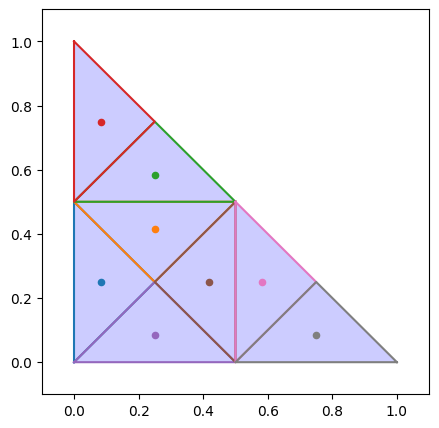

In [2]:
np.random.seed(42)

fig, ax = plt.subplots(figsize=(5, 5))
point_total = []

for triangle in triangle_set:
    # draw the triangle
    x_coords, y_coords = zip(*triangle)
    # Close the triangle by adding the first vertex at the end
    x_coords += (x_coords[0],)
    y_coords += (y_coords[0],)

    # Create the plot
    ax.plot(x_coords, y_coords)  # 'o' for circle markers at the vertices
    ax.fill(
        x_coords, y_coords, "b", alpha=0.2
    )  # Fill the triangle with a blue color and some transparency

    it = uniform_triangle(
        triangle[1] - triangle[0],
        triangle[2] - triangle[0],
    )
    # points = np.array(list(islice(it, 0, 7))) + triangle[0]
    points = triangle.mean(axis=0).reshape(-1, 2)

    ax.scatter(points[:, 0], points[:, 1], s=20)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)

    point_total.append(points)
point_total = np.concatenate(point_total)

array = np.linspace(0, 1, 9)
# mean_values = np.array([(array[i] + array[i + 1]) / 2 for i in range(len(array) - 1)]).reshape(-1,1)

mean_values = np.linspace(0, 1, 8).reshape(-1, 1)
print(point_total)
print(mean_values)

In [3]:
metal_combo = np.array(
    [
        ["Co", "Cd"],
        ["Cu", "Mn"],
        ["Ni", "Cd"],
        ["Co", "Mn"],
        ["Cu", "Cd"],
        ["Co", "Al"],
        ["Co", "Fe"],
    ]
)

np.random.seed(42)
candidates_total = []
for metal_combo_temp in metal_combo:
    a_temp = point_total.copy()
    b_temp = mean_values.copy()
    c_temp = mean_values.copy()
    np.random.shuffle(a_temp)
    np.random.shuffle(b_temp)
    np.random.shuffle(c_temp)
    candidates = np.around(
        np.concatenate((a_temp * 9.5 + 0.5, b_temp * 5, c_temp * 5), axis=1), 2
    )

    water = (20 - candidates.sum(axis=1)).reshape(-1, 1)
    candidates = np.concatenate((candidates, water), axis=1)
    candidates_total.append(candidates)
    print(metal_combo_temp)
    print(candidates)

['Co' 'Cd']
[[ 2.88  4.46  2.14  0.   10.52]
 [ 4.46  2.88  5.    4.29  3.37]
 [ 1.29  2.88  0.    2.14 13.69]
 [ 7.62  1.29  2.86  0.71  7.52]
 [ 2.88  6.04  3.57  2.86  4.65]
 [ 2.88  1.29  1.43  3.57 10.83]
 [ 1.29  7.62  0.71  1.43  8.95]
 [ 6.04  2.88  4.29  5.    1.79]]
['Cu' 'Mn']
[[ 4.46  2.88  0.71  0.   11.95]
 [ 2.88  6.04  5.    5.    1.08]
 [ 7.62  1.29  4.29  2.86  3.94]
 [ 6.04  2.88  1.43  3.57  6.08]
 [ 1.29  2.88  3.57  1.43 10.83]
 [ 2.88  1.29  0.    4.29 11.54]
 [ 1.29  7.62  2.14  2.14  6.81]
 [ 2.88  4.46  2.86  0.71  9.09]]
['Ni' 'Cd']
[[ 2.88  4.46  2.86  4.29  5.51]
 [ 6.04  2.88  1.43  2.14  7.51]
 [ 1.29  7.62  3.57  1.43  6.09]
 [ 4.46  2.88  5.    3.57  4.09]
 [ 2.88  1.29  2.14  2.86 10.83]
 [ 2.88  6.04  0.71  5.    5.37]
 [ 1.29  2.88  4.29  0.   11.54]
 [ 7.62  1.29  0.    0.71 10.38]]
['Co' 'Mn']
[[ 4.46  2.88  1.43  0.   11.23]
 [ 7.62  1.29  0.    1.43  9.66]
 [ 1.29  2.88  2.86  2.86 10.11]
 [ 2.88  4.46  4.29  3.57  4.8 ]
 [ 2.88  6.04  3.57  2.14

In [4]:
_all_candidates = []
# export the json file
# set a repeat experiment as a reference
repeat_exp = pd.DataFrame(
    {
        "substance1": ["Co"],
        "volume1": [4.0],
        "substance2": ["Mn"],
        "volume2": [4.0],
        "substance3": ["Na3Cit"],
        "volume3": [3.0],
        "substance4": ["H3BO3"],
        "volume4": [4.0],
        "substance5": ["water"],
        "volume5": [5.0],
        
        "syn_completed": ["None"],
        "storage_location": ["None"],
        "in_storage": ["None"],
        "cat_completed": ["None"], 
        
        "lsv_overpotential_-0.01": ["None"],
        "lsv_overpotential_-0.02": ["None"],
        "lsv_overpotential_-0.03": ["None"],
        "lsv_overpotential_-0.04": ["None"],
        "lsv_overpotential_-0.05": ["None"],
    }
)

repeat_index = [0]

for candidate_index in range(len(candidates_total[0])):
    # write the new candidates to the excel for the closed-loop discovery
    exp_data_out = {}
    exp_data_out["substance1"] = []
    exp_data_out["volume1"] = []
    exp_data_out["substance2"] = []
    exp_data_out["volume2"] = []
    exp_data_out["substance3"] = []
    exp_data_out["volume3"] = []
    exp_data_out["substance4"] = []
    exp_data_out["volume4"] = []
    exp_data_out["substance5"] = []
    exp_data_out["volume5"] = []

    exp_data_out["syn_completed"] = []
    exp_data_out["storage_location"] = []
    exp_data_out["in_storage"] = []

    exp_data_out["cat_completed"] = []
    exp_data_out["lsv_overpotential_-0.01"] = []
    exp_data_out["lsv_overpotential_-0.02"] = []
    exp_data_out["lsv_overpotential_-0.03"] = []
    exp_data_out["lsv_overpotential_-0.04"] = []
    exp_data_out["lsv_overpotential_-0.05"] = []

    exp_data_out = pd.DataFrame(exp_data_out)

    for metal_index in range(len(metal_combo)):
        if len(exp_data_out) in repeat_index:
            exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)

        temp = pd.DataFrame(
            {
                "substance1": [metal_combo[metal_index][0]],
                "volume1": [candidates_total[metal_index][candidate_index][0]],
                "substance2": [metal_combo[metal_index][1]],
                "volume2": [candidates_total[metal_index][candidate_index][1]],
                "substance3": "Na3Cit",
                "volume3": [candidates_total[metal_index][candidate_index][2]],
                "substance4": "H3BO3",
                "volume4": [candidates_total[metal_index][candidate_index][3]],
                "substance5": "water",
                "volume5": [candidates_total[metal_index][candidate_index][4]],
                "syn_completed": ["None"],
                "storage_location": ["None"],
                "in_storage": ["None"],
                "cat_completed": ["None"], 
                "lsv_overpotential_-0.01": ["None"],
                "lsv_overpotential_-0.02": ["None"],
                "lsv_overpotential_-0.03": ["None"],
                "lsv_overpotential_-0.04": ["None"],
                "lsv_overpotential_-0.05": ["None"],
            }
        )

        for repeat in range(1):
            exp_data_out = pd.concat((exp_data_out, temp), ignore_index=True)
    if len(exp_data_out) in repeat_index:
        exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
    display(exp_data_out)
    _all_candidates.append(exp_data_out)
    exp_data_out.to_json(f"./initial_sampling_{candidate_index}.json")

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,2.88,Cd,4.46,Na3Cit,2.14,H3BO3,0.00,water,10.52,None,None,None,None,None,None,None,None,None
2,Cu,4.46,Mn,2.88,Na3Cit,0.71,H3BO3,0.00,water,11.95,None,None,None,None,None,None,None,None,None
3,Ni,2.88,Cd,4.46,Na3Cit,2.86,H3BO3,4.29,water,5.51,None,None,None,None,None,None,None,None,None
4,Co,4.46,Mn,2.88,Na3Cit,1.43,H3BO3,0.00,water,11.23,None,None,None,None,None,None,None,None,None
5,Cu,2.88,Cd,1.29,Na3Cit,1.43,H3BO3,0.71,water,13.69,None,None,None,None,None,None,None,None,None
6,Co,2.88,Al,6.04,Na3Cit,0.71,H3BO3,2.14,water,8.23,None,None,None,None,None,None,None,None,None
7,Co,2.88,Fe,6.04,Na3Cit,2.14,H3BO3,2.14,water,6.80,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,4.29,water,3.37,None,None,None,None,None,None,None,None,None
2,Cu,2.88,Mn,6.04,Na3Cit,5.00,H3BO3,5.00,water,1.08,None,None,None,None,None,None,None,None,None
3,Ni,6.04,Cd,2.88,Na3Cit,1.43,H3BO3,2.14,water,7.51,None,None,None,None,None,None,None,None,None
4,Co,7.62,Mn,1.29,Na3Cit,0.00,H3BO3,1.43,water,9.66,None,None,None,None,None,None,None,None,None
5,Cu,2.88,Cd,6.04,Na3Cit,0.00,H3BO3,1.43,water,9.65,None,None,None,None,None,None,None,None,None
6,Co,2.88,Al,4.46,Na3Cit,2.14,H3BO3,5.00,water,5.52,None,None,None,None,None,None,None,None,None
7,Co,2.88,Fe,1.29,Na3Cit,0.00,H3BO3,4.29,water,11.54,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,1.29,Cd,2.88,Na3Cit,0.00,H3BO3,2.14,water,13.69,None,None,None,None,None,None,None,None,None
2,Cu,7.62,Mn,1.29,Na3Cit,4.29,H3BO3,2.86,water,3.94,None,None,None,None,None,None,None,None,None
3,Ni,1.29,Cd,7.62,Na3Cit,3.57,H3BO3,1.43,water,6.09,None,None,None,None,None,None,None,None,None
4,Co,1.29,Mn,2.88,Na3Cit,2.86,H3BO3,2.86,water,10.11,None,None,None,None,None,None,None,None,None
5,Cu,2.88,Cd,4.46,Na3Cit,3.57,H3BO3,3.57,water,5.52,None,None,None,None,None,None,None,None,None
6,Co,7.62,Al,1.29,Na3Cit,2.86,H3BO3,3.57,water,4.66,None,None,None,None,None,None,None,None,None
7,Co,4.46,Fe,2.88,Na3Cit,0.71,H3BO3,0.71,water,11.24,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,7.62,Cd,1.29,Na3Cit,2.86,H3BO3,0.71,water,7.52,None,None,None,None,None,None,None,None,None
2,Cu,6.04,Mn,2.88,Na3Cit,1.43,H3BO3,3.57,water,6.08,None,None,None,None,None,None,None,None,None
3,Ni,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,3.57,water,4.09,None,None,None,None,None,None,None,None,None
4,Co,2.88,Mn,4.46,Na3Cit,4.29,H3BO3,3.57,water,4.80,None,None,None,None,None,None,None,None,None
5,Cu,1.29,Cd,2.88,Na3Cit,2.14,H3BO3,0.00,water,13.69,None,None,None,None,None,None,None,None,None
6,Co,1.29,Al,7.62,Na3Cit,0.00,H3BO3,4.29,water,6.80,None,None,None,None,None,None,None,None,None
7,Co,2.88,Fe,4.46,Na3Cit,1.43,H3BO3,3.57,water,7.66,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,2.88,Cd,6.04,Na3Cit,3.57,H3BO3,2.86,water,4.65,None,None,None,None,None,None,None,None,None
2,Cu,1.29,Mn,2.88,Na3Cit,3.57,H3BO3,1.43,water,10.83,None,None,None,None,None,None,None,None,None
3,Ni,2.88,Cd,1.29,Na3Cit,2.14,H3BO3,2.86,water,10.83,None,None,None,None,None,None,None,None,None
4,Co,2.88,Mn,6.04,Na3Cit,3.57,H3BO3,2.14,water,5.37,None,None,None,None,None,None,None,None,None
5,Cu,7.62,Cd,1.29,Na3Cit,4.29,H3BO3,2.86,water,3.94,None,None,None,None,None,None,None,None,None
6,Co,4.46,Al,2.88,Na3Cit,3.57,H3BO3,0.71,water,8.38,None,None,None,None,None,None,None,None,None
7,Co,7.62,Fe,1.29,Na3Cit,2.86,H3BO3,2.86,water,5.37,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,2.88,Cd,1.29,Na3Cit,1.43,H3BO3,3.57,water,10.83,None,None,None,None,None,None,None,None,None
2,Cu,2.88,Mn,1.29,Na3Cit,0.00,H3BO3,4.29,water,11.54,None,None,None,None,None,None,None,None,None
3,Ni,2.88,Cd,6.04,Na3Cit,0.71,H3BO3,5.00,water,5.37,None,None,None,None,None,None,None,None,None
4,Co,2.88,Mn,1.29,Na3Cit,5.00,H3BO3,5.00,water,5.83,None,None,None,None,None,None,None,None,None
5,Cu,6.04,Cd,2.88,Na3Cit,0.71,H3BO3,4.29,water,6.08,None,None,None,None,None,None,None,None,None
6,Co,6.04,Al,2.88,Na3Cit,1.43,H3BO3,2.86,water,6.79,None,None,None,None,None,None,None,None,None
7,Co,1.29,Fe,2.88,Na3Cit,3.57,H3BO3,5.00,water,7.26,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,1.29,Cd,7.62,Na3Cit,0.71,H3BO3,1.43,water,8.95,None,None,None,None,None,None,None,None,None
2,Cu,1.29,Mn,7.62,Na3Cit,2.14,H3BO3,2.14,water,6.81,None,None,None,None,None,None,None,None,None
3,Ni,1.29,Cd,2.88,Na3Cit,4.29,H3BO3,0.00,water,11.54,None,None,None,None,None,None,None,None,None
4,Co,1.29,Mn,7.62,Na3Cit,2.14,H3BO3,0.71,water,8.24,None,None,None,None,None,None,None,None,None
5,Cu,4.46,Cd,2.88,Na3Cit,5.00,H3BO3,5.00,water,2.66,None,None,None,None,None,None,None,None,None
6,Co,1.29,Al,2.88,Na3Cit,4.29,H3BO3,1.43,water,10.11,None,None,None,None,None,None,None,None,None
7,Co,6.04,Fe,2.88,Na3Cit,5.00,H3BO3,0.00,water,6.08,None,None,None,None,None,None,None,None,None


,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,substance5,volume5,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05
0,Co,4.00,Mn,4.00,Na3Cit,3.00,H3BO3,4.00,water,5.00,None,None,None,None,None,None,None,None,None
1,Co,6.04,Cd,2.88,Na3Cit,4.29,H3BO3,5.00,water,1.79,None,None,None,None,None,None,None,None,None
2,Cu,2.88,Mn,4.46,Na3Cit,2.86,H3BO3,0.71,water,9.09,None,None,None,None,None,None,None,None,None
3,Ni,7.62,Cd,1.29,Na3Cit,0.00,H3BO3,0.71,water,10.38,None,None,None,None,None,None,None,None,None
4,Co,6.04,Mn,2.88,Na3Cit,0.71,H3BO3,4.29,water,6.08,None,None,None,None,None,None,None,None,None
5,Cu,1.29,Cd,7.62,Na3Cit,2.86,H3BO3,2.14,water,6.09,None,None,None,None,None,None,None,None,None
6,Co,2.88,Al,1.29,Na3Cit,5.00,H3BO3,0.00,water,10.83,None,None,None,None,None,None,None,None,None
7,Co,1.29,Fe,7.62,Na3Cit,4.29,H3BO3,1.43,water,5.37,None,None,None,None,None,None,None,None,None


In [5]:
pd.concat(_all_candidates, ignore_index=True).to_json(f"./initial_sampling_all.json")

In [5]:
exp_data = exp_data_out
exp_data = exp_data.replace({np.nan: None, "None": None})

In [6]:
from botorch_tool.active_learning import generate_new_exp_SO

In [7]:
exp_data["lsv_overpotential_-0.05"] = np.array([1,2,3,4,5,6,7,8]).astype(np.float64)

In [8]:
exp_index = 0

In [9]:
from multiprocessing.pool import ThreadPool
# start a thread to see if we should start an experimental design 
pool = ThreadPool(processes=1)
async_result = pool.apply_async(generate_new_exp_SO, (exp_data, exp_index)) # tuple of args for foo

In [ ]:
candidate_row, repeat_exp = async_result.get()

In [11]:
exp_data.loc[len(exp_data)] = repeat_exp
exp_data.loc[len(exp_data)] = candidate_row

In [21]:
exp_data["syn_completed"] = exp_data["syn_completed"].values

In [ ]:
exp_data == None

In [ ]:
exp_data["syn_completed"].values == None

In [ ]:
exp_data["in_storage"].values == True